# Quantum-kernel SVM vs classical models on real data — Track 2 (QML)

**Question.** Does a quantum-kernel SVM beat a classical SVM on a real, small dataset when every model gets the *same features*, the *same train/test splits* and the *same hyperparameter tuning*? Where does the classical model win, and why?

Everything is **classical simulation** (NumPy statevectors checked against Qiskit, Qiskit Aer, and the bundled `FakeTorino` noise model run locally). No quantum hardware or IBM account is used.

## Assumptions
* **Data:** scikit-learn's bundled Wisconsin breast-cancer set (569 patients, 30 features, malignant vs benign) and wine (178 samples, 13 features, cultivar 1 vs rest). No external download.
* **Features:** StandardScaler → PCA(n = number of qubits) → MinMax to [0, π], fitted **on each training fold only** and then applied to its test fold.
* **Quantum kernel:** fidelity kernel $k(x,y)=|\langle\phi(x)|\phi(y)\rangle|^2$ of Qiskit's `zz_feature_map` (2 repetitions, linear entanglement); a bandwidth $s$ multiplies the features first (Shaydulin & Wild 2022). $s=1$ is the common tutorial setting.
* **Protocol:** 3×5 repeated stratified CV (15 outer folds, same for every model); every hyperparameter (C, RBF γ, quantum bandwidth s) chosen by an inner 3-fold CV on the outer training fold; paired differences tested with the Nadeau–Bengio corrected resampled t-test.
* **Noise:** kernel entries estimated from compute–uncompute circuits with 1000 shots, ideal and with the FakeTorino model (a historical calibration snapshot, run locally) on a 40/30 subset.
* **Scope:** 2–12 qubits; all of it is classically simulable, so no quantum advantage is possible or claimed here.

In [1]:
import numpy as np, json
from qkbench.bench import load, preprocess, benchmark
from qkbench.kernels import quantum_kernel, rbf_kernel, feature_map_circuit
X, y, desc = load("breast_cancer"); print(desc, "| fraction benign:", round(y.mean(), 3))
feature_map_circuit(4).draw(fold=-1)

Wisconsin breast-cancer diagnosis (569 samples, 30 features, malignant vs benign) | fraction benign: 0.627


┌───┐┌───────────┐                                          ┌───┐         ┌───────────┐                                                                                                                                                                                          
0: ┤ H ├┤ P(2*x[0]) ├──■────────────────────────────────────■──┤ H ├─────────┤ P(2*x[0]) ├──────────────────────────────────────────────────────■────────────────────────────────────────■──────────────────────────────────────────────────────────────────────────────────────────
   ├───┤├───────────┤┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘               ┌───┐         ┌───────────┐          ┌─┴─┐┌──────────────────────────────┐    ┌─┴─┐                                                                                        
1: ┤ H ├┤ P(2*x[1]) ├┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├┤ X ├──■────────────────────────────────────■──┤ H ├─────────┤ P(2*x[1]) ├──────────┤ X ├┤ P((-π + x[0])*(-π + x[1])*2) ├────┤ X ├──────■────────────────────────────────────■────────────────────────────────────────────
   ├───┤├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐└───┘         └───────────┘          └───┘└────────────┬───┬─────────────┘┌───┴───┴───┐┌─┴─┐┌──────────────────────────────┐┌─┴─┐                                          
2: ┤ H ├┤ P(2*x[2]) ├──────────────────────────────────────────┤ X ├┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■────────────────────────────────────■───────────────┤ H ├──────────────┤ P(2*x[2]) ├┤ X ├┤ P((-π + x[1])*(-π + x[2])*2) ├┤ X ├──■────────────────────────────────────■──
   ├───┤├───────────┤                                          └───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐             ├───┤              ├───────────┤└───┘└──────────────────────────────┘└───┘┌─┴─┐┌──────────────────────────────┐┌─┴─┐
3: ┤ H ├┤ P(2*x[3]) ├────────────────────────────────────────────────────────────────────────────────────┤ X ├┤ P((-π + x[2])*(-π + x[3])*2) ├┤ X ├─────────────┤ H ├──────────────┤ P(2*x[3]) ├──────────────────────────────────────────┤ X ├┤ P((-π + x[2])*(-π + x[3])*2) ├┤ X ├
   └───┘└───────────┘                                                                                    └───┘└──────────────────────────────┘└───┘             └───┘              └───────────┘                                          └───┘└──────────────────────────────┘└───┘

## 1. One quick fold-safe comparison (4 qubits, one outer CV repeat)

In [2]:
r = benchmark("breast_cancer", [4], n_splits=5, n_repeats=1)
s = r["summary"][0]
print({k: round(v, 3) for k, v in s["mean_acc"].items()})
print("tuned quantum − RBF:", {k: (np.round(v, 3) if not isinstance(v, int) else v) for k, v in s["qsvm_tuned_minus_rbf"].items()})
print("chosen bandwidths per fold:", s["chosen_bandwidths"])

{'qsvm_tuned': 0.954, 'qsvm_s1': 0.807, 'rbf_svm': 0.963, 'logreg': 0.965}
tuned quantum − RBF: {'mean': np.float64(-0.009), 'ci95': array([-0.039,  0.022]), 'p_value': np.float64(0.47), 'n_folds': 5}
chosen bandwidths per fold: [0.05, 0.1, 0.1, 0.05, 0.05]


## 2. Full saved study (`python -m qkbench.experiments`, ≈3 min)

In [3]:
for d in ("breast_cancer", "wine"):
    rec = json.load(open(f"../artifacts/e1_benchmark_{d}.json"))
    print(d, "| RBF on all features:", round(rec["full_feature_rbf"]["mean_acc"], 3))
    for s in rec["summary"]:
        q = s["qsvm_tuned_minus_rbf"]
        print(f"  {s['n_qubits']:2d} qubits  tuned-Q {s['mean_acc']['qsvm_tuned']:.3f}  Q(s=1) {s['mean_acc']['qsvm_s1']:.3f}  RBF {s['mean_acc']['rbf_svm']:.3f}  LR {s['mean_acc']['logreg']:.3f}   Q−RBF {q['mean']:+.3f} [{q['ci95'][0]:+.3f}, {q['ci95'][1]:+.3f}]")

breast_cancer | RBF on all features: 0.977
   2 qubits  tuned-Q 0.940  Q(s=1) 0.895  RBF 0.944  LR 0.954   Q−RBF -0.005 [-0.014, +0.004]
   4 qubits  tuned-Q 0.955  Q(s=1) 0.818  RBF 0.961  LR 0.960   Q−RBF -0.006 [-0.026, +0.013]
   6 qubits  tuned-Q 0.960  Q(s=1) 0.806  RBF 0.965  LR 0.972   Q−RBF -0.005 [-0.019, +0.010]
   8 qubits  tuned-Q 0.967  Q(s=1) 0.769  RBF 0.975  LR 0.974   Q−RBF -0.008 [-0.024, +0.008]
  10 qubits  tuned-Q 0.966  Q(s=1) 0.715  RBF 0.977  LR 0.974   Q−RBF -0.011 [-0.028, +0.007]
  12 qubits  tuned-Q 0.965  Q(s=1) 0.660  RBF 0.970  LR 0.972   Q−RBF -0.005 [-0.023, +0.013]
wine | RBF on all features: 0.992
   2 qubits  tuned-Q 0.968  Q(s=1) 0.883  RBF 0.976  LR 0.936   Q−RBF -0.007 [-0.023, +0.008]
   4 qubits  tuned-Q 0.966  Q(s=1) 0.857  RBF 0.985  LR 0.944   Q−RBF -0.019 [-0.050, +0.012]
   6 qubits  tuned-Q 0.977  Q(s=1) 0.796  RBF 0.989  LR 0.985   Q−RBF -0.011 [-0.042, +0.020]
   8 qubits  tuned-Q 0.987  Q(s=1) 0.699  RBF 0.990  LR 0.985   Q−RBF -0.004 

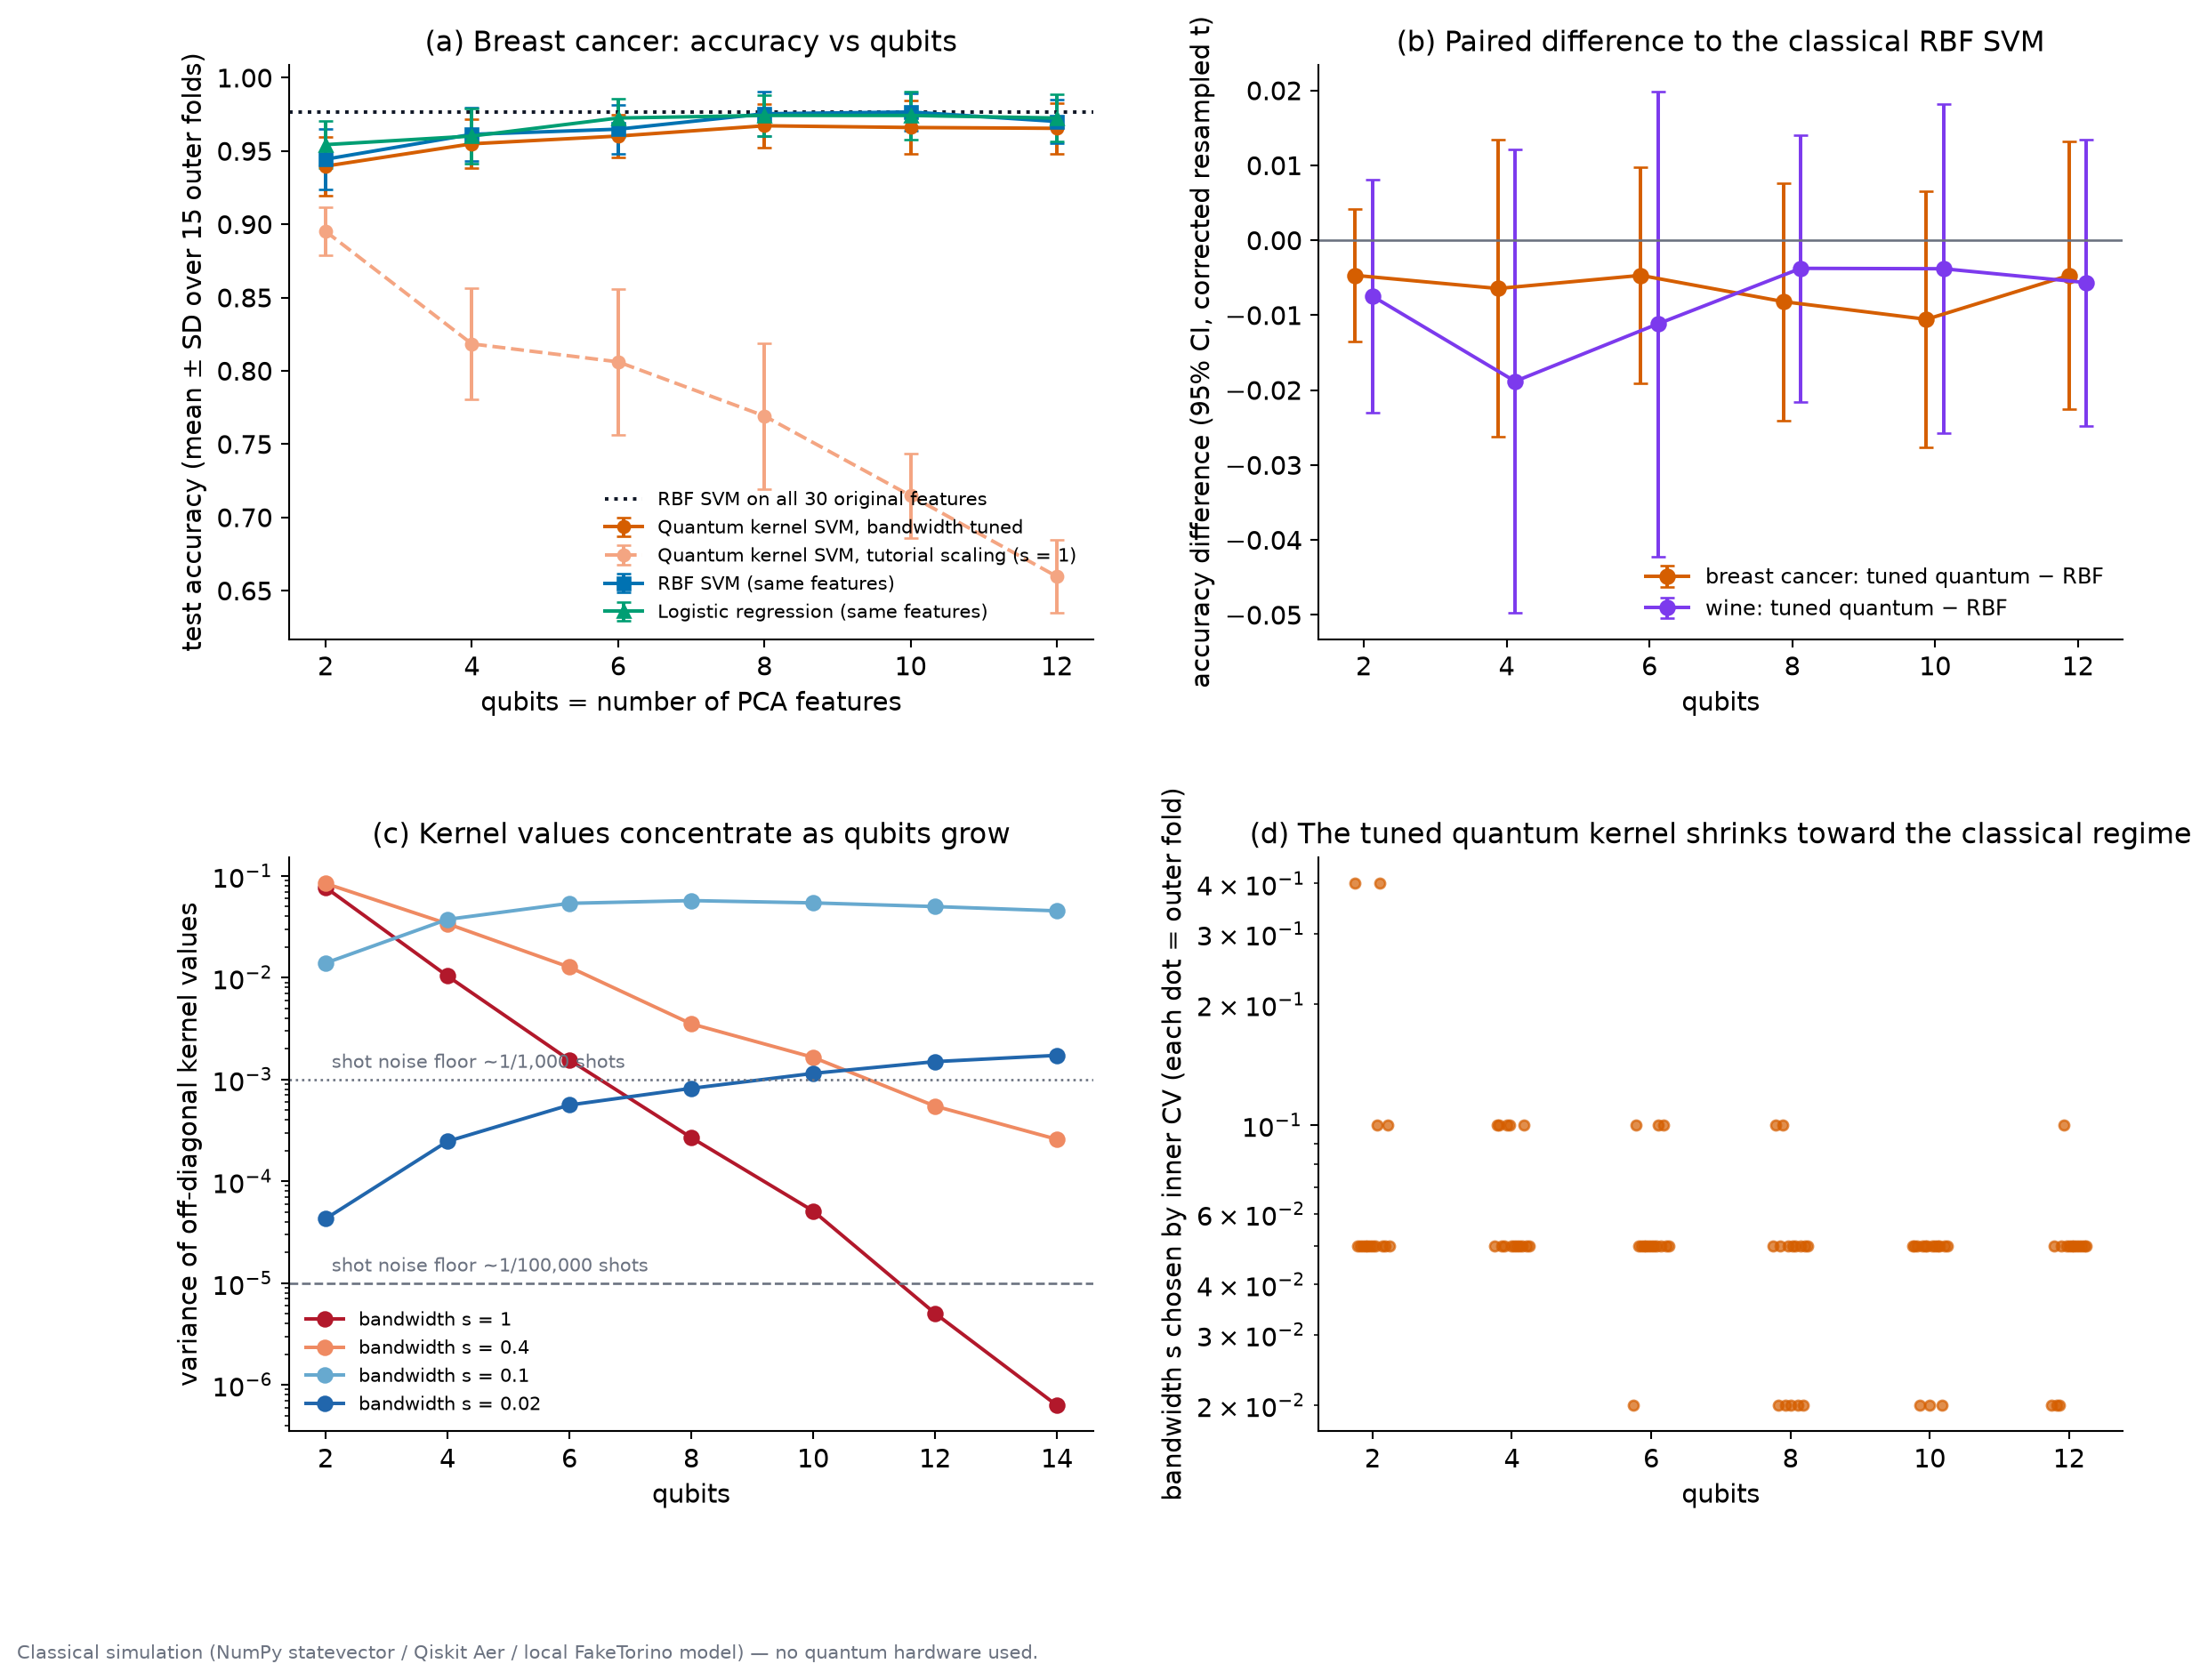

In [4]:
from IPython.display import Image, display
display(Image("../figures/main_figure.png"))

## 3. Why the quantum kernel loses: concentration
At $s=1$ kernel values between different patients collapse toward 0 as qubits grow, so the Gram matrix approaches the identity and the SVM can only memorise. Cross-validation fixes this by choosing a small bandwidth — which makes the quantum kernel smooth and close to a classical one (geometric difference $g\approx 1$–3 to an RBF kernel).

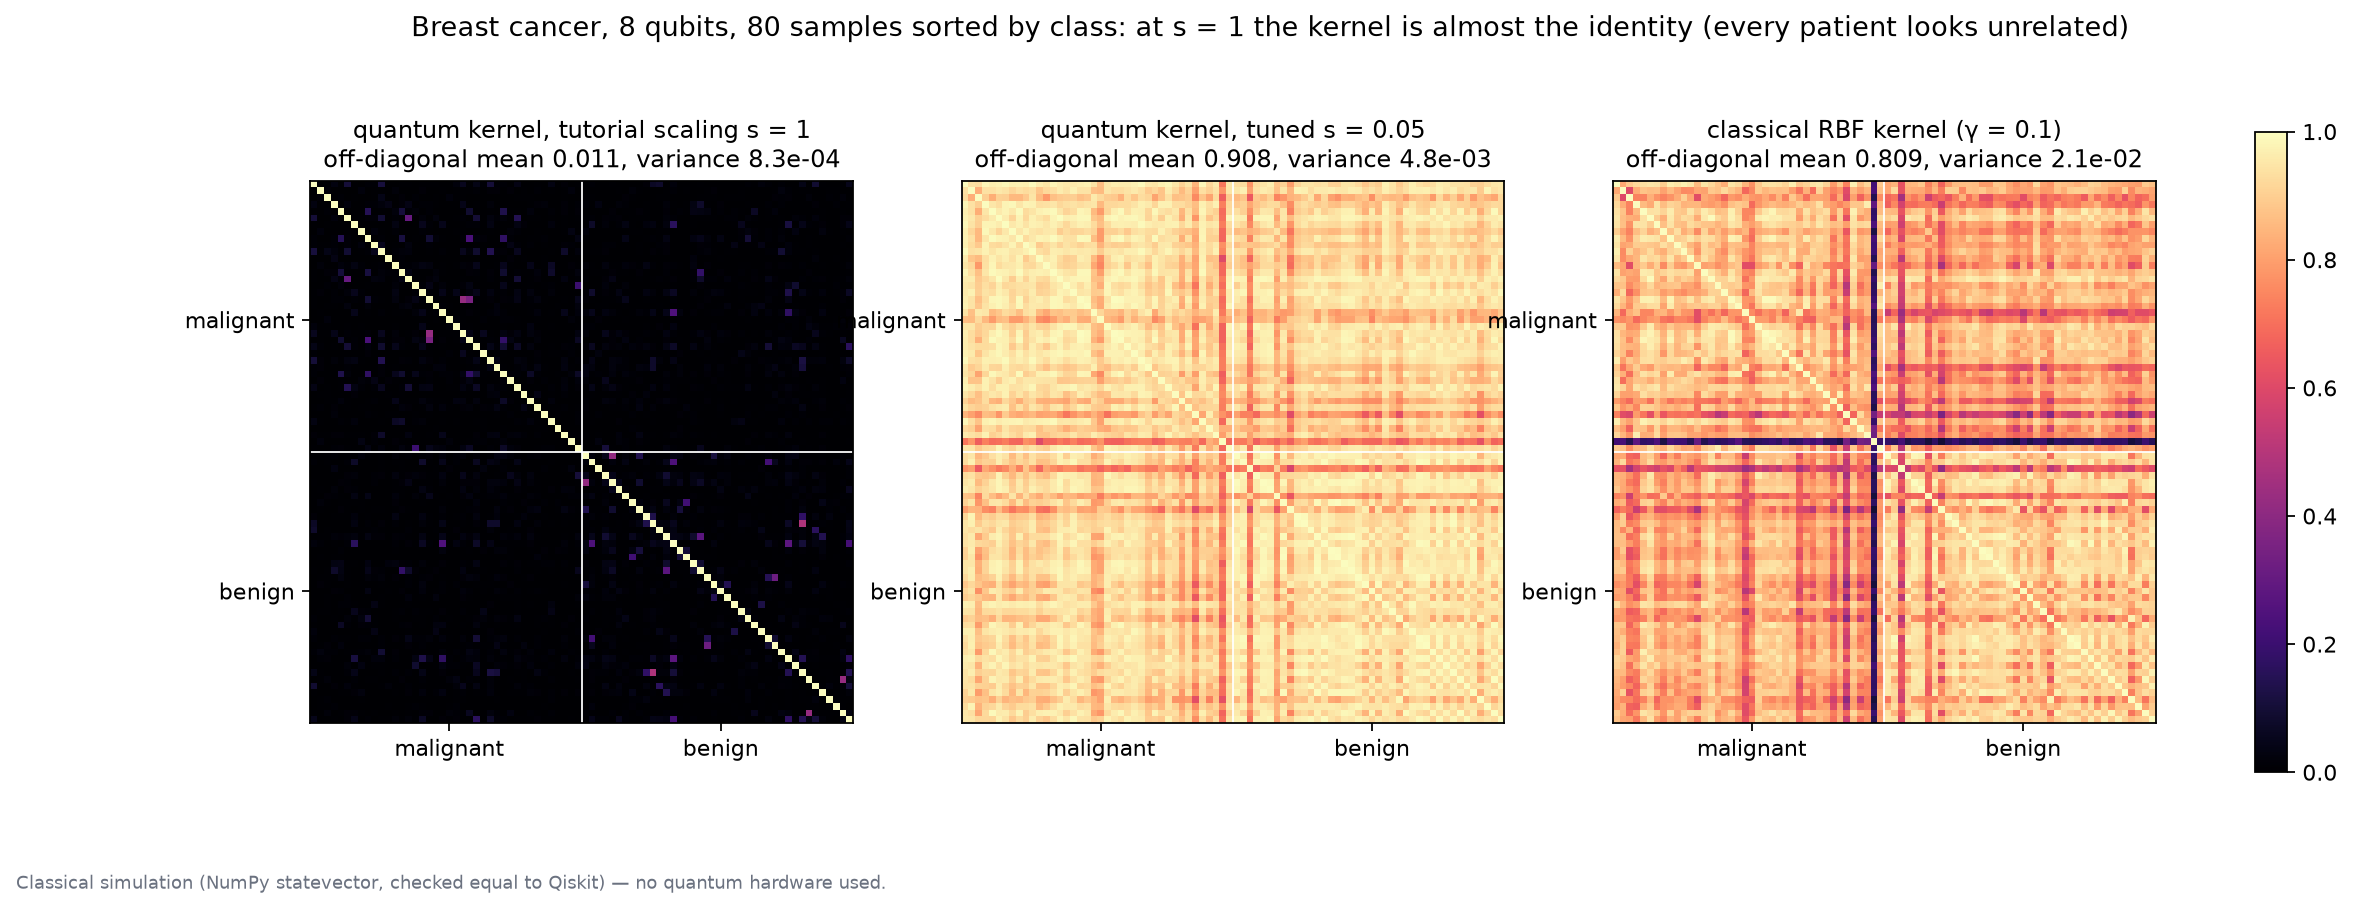

2 qubits, s = 1.0  off-diag variance 7.7e-02  g = 28.10
2 qubits, s = 0.02  off-diag variance 4.3e-05  g = 1.19
4 qubits, s = 1.0  off-diag variance 1.0e-02  g = 26.12
4 qubits, s = 0.02  off-diag variance 2.5e-04  g = 1.53
6 qubits, s = 1.0  off-diag variance 1.6e-03  g = 5.75
6 qubits, s = 0.02  off-diag variance 5.6e-04  g = 1.69
8 qubits, s = 1.0  off-diag variance 2.7e-04  g = 3.41
8 qubits, s = 0.02  off-diag variance 8.2e-04  g = 1.81
10 qubits, s = 1.0  off-diag variance 5.1e-05  g = 2.49
10 qubits, s = 0.02  off-diag variance 1.1e-03  g = 1.91
12 qubits, s = 1.0  off-diag variance 5.0e-06  g = 1.77
12 qubits, s = 0.02  off-diag variance 1.5e-03  g = 2.03
14 qubits, s = 1.0  off-diag variance 6.3e-07  g = 1.49
14 qubits, s = 0.02  off-diag variance 1.7e-03  g = 2.14


In [5]:
display(Image("../figures/kernel_matrices.png"))
co = json.load(open("../artifacts/e2_concentration.json"))
for r_ in co["rows"]:
    if r_["bandwidth"] in (1.0, 0.02): print(r_["n_qubits"], "qubits, s =", r_["bandwidth"], " off-diag variance %.1e" % r_["offdiag_var"], " g = %.2f" % r_["geometric_difference_min_over_gamma"])

## 4. Hardware reality: shots, noise and circuit counts

4 qubits: 1980 circuits; {'exact': (0.8, 0.0), 'ideal_shots': (0.8666666666666667, 0.01), 'faketorino_noisy': (0.7666666666666667, 0.266)}
6 qubits: 1980 circuits; {'exact': (0.9666666666666667, 0.0), 'ideal_shots': (0.9333333333333333, 0.012), 'faketorino_noisy': (0.8666666666666667, 0.307)}
overlap circuits for the full breast-cancer set, per CV fold: {'train_pairs': 103285, 'test_pairs': 51870}


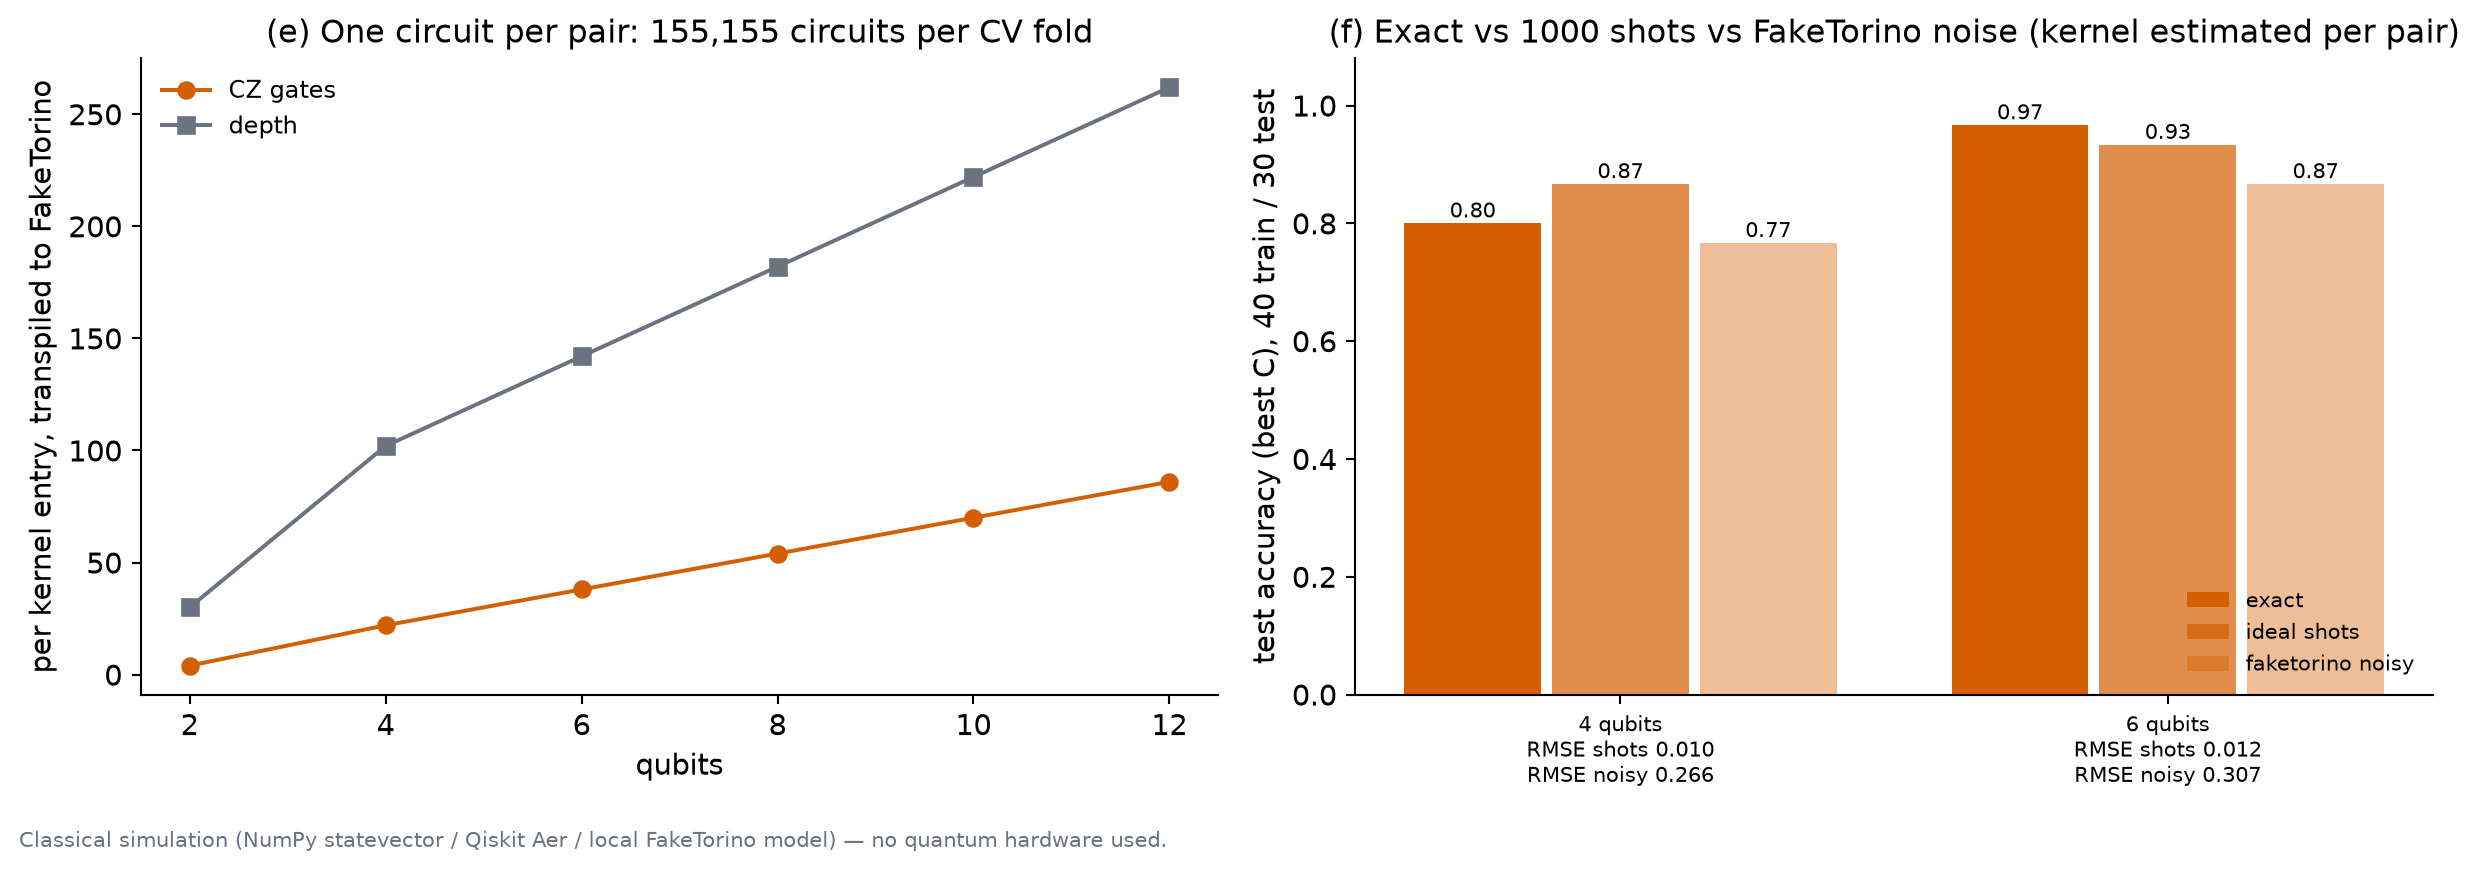

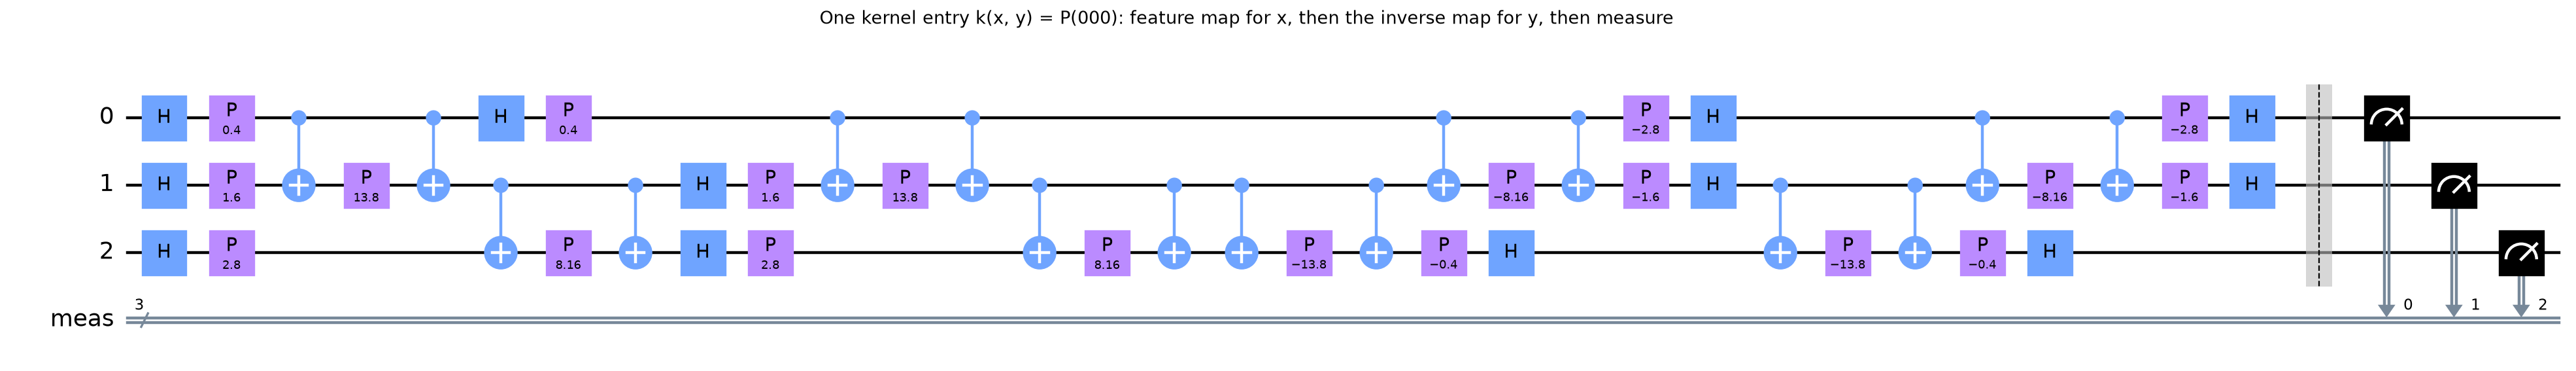

In [6]:
e3 = json.load(open("../artifacts/e3_noise.json"))
for r_ in e3["rows"]:
    print(r_["n_qubits"], "qubits:", r_["circuits"], "circuits;", {k: (max(r_[k]["test_acc_by_C"].values()), round(r_[k]["kernel_rmse_vs_exact"], 3)) for k in ("exact", "ideal_shots", "faketorino_noisy")})
print("overlap circuits for the full breast-cancer set, per CV fold:", e3["full_dataset_circuits_per_fold"])
display(Image("../figures/hardware_figure.png")); display(Image("../figures/overlap_circuit_n3.png"))

## Conclusions (simulation only)
* With identical features, splits and tuning, the tuned quantum-kernel SVM **never beats** the RBF SVM on either dataset (all differences ≤ 0, confidence intervals include 0); an RBF SVM on all original features is the best model.
* At the tutorial scaling the quantum kernel **concentrates** and accuracy falls steadily with qubits.
* On the FakeTorino noise model each kernel entry is distorted far more than by shot noise, and the full dataset needs ~10⁵ circuits per fold.